In [1]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install torch torchvision pandas numpy Pillow matplotlib scikit-learn opencv-python

Note: you may need to restart the kernel to use updated packages.


In [1]:

import torch
import torchvision
import pandas
import numpy
import PIL
import matplotlib
import sklearn
import cv2

print("All required packages imported successfully!")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


All required packages imported successfully!
PyTorch: 2.15.0+cu134
Torchvision: 0.29.2+cu134
OpenCV: 5.0.0
CUDA available: True
GPU: NVIDIA RTX A4000 Laptop GPU


In [1]:
import sys
print("Python:", sys.version)
print("Executable:", sys.executable)

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Executable: D:\ML\Computer Vision\EmotionDetectionProject\.venv\Scripts\python.exe


In [5]:

import random
import time
import copy
import json
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader


# ==========================================
# 1. Configuration
# ==========================================

SEED = 42

BATCH_SIZE = 32
EPOCHS = 60

LEARNING_RATE = 0.0001
WEIGHT_DECAY = 0.0001

PATIENCE = 15
NUM_CLASSES = 7

CLASS_NAMES = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]


# ==========================================
# 2. Project and Dataset Paths
# ==========================================

PROJECT_DIR = Path(
    r"D:\ML\Computer Vision\EmotionDetectionProject"
)

CSV_PATH = (
    PROJECT_DIR
    / "fer2013"
    / "fer2013"
    / "fer2013.csv"
)

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "efficientnet"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = (
    CHECKPOINT_DIR / "best_efficientnet_emotion.pth"
)

HISTORY_PATH = (
    OUTPUT_DIR / "training_history_efficientnet.json"
)


print("=" * 60)
print("EfficientNet-B0 - FER2013")
print("=" * 60)

print("Project directory:", PROJECT_DIR)
print("CSV path:", CSV_PATH)
print("CSV exists:", CSV_PATH.exists())

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"FER2013 dataset not found:\n{CSV_PATH}"
    )

print("Dataset found successfully!")


# ==========================================
# 3. Reproducibility
# ==========================================

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ==========================================
# 4. Device
# ==========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nUsing device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

    torch.backends.cudnn.benchmark = True


# ==========================================
# 5. FER2013 Dataset
# ==========================================

class FER2013Dataset(Dataset):

    def __init__(
        self,
        csv_file,
        transform=None,
        usage="Training"
    ):

        self.data = pd.read_csv(csv_file)

        self.data = (
            self.data[
                self.data["Usage"] == usage
            ]
            .reset_index(drop=True)
        )

        self.transform = transform

        print(
            f"{usage} dataset loaded:",
            len(self.data)
        )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        pixels = self.data.iloc[idx]["pixels"]

        pixels = np.fromstring(
            pixels,
            dtype=np.uint8,
            sep=" "
        )

        image = pixels.reshape(48, 48)

        image = Image.fromarray(image)

        label = int(
            self.data.iloc[idx]["emotion"]
        )

        if self.transform:
            image = self.transform(image)

        return image, label


# ==========================================
# 6. Image Transformations
# ==========================================

train_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.Grayscale(
        num_output_channels=3
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])


val_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.Grayscale(
        num_output_channels=3
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])


# ==========================================
# 7. Load Training and Validation Data
# ==========================================

train_dataset = FER2013Dataset(
    CSV_PATH,
    transform=train_transform,
    usage="Training"
)

val_dataset = FER2013Dataset(
    CSV_PATH,
    transform=val_transform,
    usage="PublicTest"
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


print("\nDataset loading completed")

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


# ==========================================
# 8. Load EfficientNet-B0
# ==========================================

print("\nLoading EfficientNet-B0...")

weights = models.EfficientNet_B0_Weights.DEFAULT

model = models.efficientnet_b0(
    weights=weights
)


# Replace final classification layer

num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    NUM_CLASSES
)

model = model.to(device)

print("EfficientNet-B0 loaded successfully")

print("Number of classes:", NUM_CLASSES)


# ==========================================
# 9. Test Model Input and Output
# ==========================================

sample_images, sample_labels = next(
    iter(train_loader)
)

sample_images = sample_images.to(device)

model.eval()

with torch.no_grad():

    outputs = model(sample_images)

print("\nModel Test")

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (
    BATCH_SIZE,
    NUM_CLASSES
), "Incorrect model output shape!"

print("Model test passed successfully!")


# ==========================================
# 10. Loss and Optimizer
# ==========================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ==========================================
# 11. Learning Rate Scheduler
# ==========================================

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-6
)


# ==========================================
# 12. Training Configuration
# ==========================================

best_val_acc = 0.0

epochs_no_improve = 0

best_model_wts = copy.deepcopy(
    model.state_dict()
)

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "learning_rate": [],
    "epoch_time": []
}


# ==========================================
# 13. Training Loop
# ==========================================

print("\n" + "=" * 60)

print("Starting EfficientNet-B0 Fine-Tuning")

print("=" * 60)


for epoch in range(EPOCHS):

    start_time = time.time()

    # --------------------------------------
    # Training Phase
    # --------------------------------------

    model.train()

    running_loss = 0.0

    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)


    train_loss = running_loss / total

    train_acc = (
        100.0 * correct / total
    )


    # --------------------------------------
    # Validation Phase
    # --------------------------------------

    model.eval()

    val_running_loss = 0.0

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            val_running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)


    val_loss = (
        val_running_loss / val_total
    )

    val_acc = (
        100.0 * val_correct / val_total
    )


    # --------------------------------------
    # Scheduler
    # --------------------------------------

    scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - start_time


    # --------------------------------------
    # Save Training History
    # --------------------------------------

    history["train_loss"].append(train_loss)

    history["train_acc"].append(train_acc)

    history["val_loss"].append(val_loss)

    history["val_acc"].append(val_acc)

    history["learning_rate"].append(current_lr)

    history["epoch_time"].append(epoch_time)


    # --------------------------------------
    # Print Epoch Results
    # --------------------------------------

    print("\n" + "=" * 60)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}]"
    )

    print("=" * 60)

    print(
        f"Time: {epoch_time:.1f} seconds"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: {train_acc:.2f}%"
    )

    print(
        f"Validation Loss: {val_loss:.4f}"
    )

    print(
        f"Validation Accuracy: {val_acc:.2f}%"
    )

    print(
        f"Learning Rate: {current_lr:.7f}"
    )


    # --------------------------------------
    # Save Best Model
    # --------------------------------------

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        epochs_no_improve = 0

        best_model_wts = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": best_model_wts,
                "best_val_accuracy": best_val_acc,
                "history": history
            },
            BEST_MODEL_PATH
        )

        print("\nBest model saved!")

    else:

        epochs_no_improve += 1

        print(
            "\nNo improvement:",
            epochs_no_improve,
            "/",
            PATIENCE
        )


    # --------------------------------------
    # Save History
    # --------------------------------------

    with open(
        HISTORY_PATH,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            history,
            file,
            indent=4
        )


    # --------------------------------------
    # Early Stopping
    # --------------------------------------

    if epochs_no_improve >= PATIENCE:

        print("\nEarly Stopping activated.")

        break


# ==========================================
# 14. Restore Best Model
# ==========================================

model.load_state_dict(
    best_model_wts
)


# ==========================================
# 15. Final Training Summary
# ==========================================

print("\n" + "=" * 60)

print("EFFICIENTNET-B0 TRAINING COMPLETED")

print("=" * 60)

print(
    f"Best Validation Accuracy: {best_val_acc:.2f}%"
)

print(
    "Best model saved at:",
    BEST_MODEL_PATH
)

print(
    "Training history saved at:",
    HISTORY_PATH
)

print("\nPrivateTest was not used during training.")

print("It will be used later for final evaluation.")


EfficientNet-B0 - FER2013
Project directory: D:\ML\Computer Vision\EmotionDetectionProject
CSV path: D:\ML\Computer Vision\EmotionDetectionProject\fer2013\fer2013\fer2013.csv
CSV exists: True
Dataset found successfully!

Using device: cuda
GPU: NVIDIA RTX A4000 Laptop GPU
Training dataset loaded: 28709
PublicTest dataset loaded: 3589

Dataset loading completed
Training samples: 28709
Validation samples: 3589
Training batches: 898
Validation batches: 113

Loading EfficientNet-B0...
EfficientNet-B0 loaded successfully
Number of classes: 7

Model Test
Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 7])
Model test passed successfully!

Starting EfficientNet-B0 Fine-Tuning

Epoch [1/60]
Time: 138.2 seconds
Train Loss: 1.2692
Train Accuracy: 51.58%
Validation Loss: 1.0313
Validation Accuracy: 60.77%
Learning Rate: 0.0000999

Best model saved!

Epoch [2/60]
Time: 139.6 seconds
Train Loss: 0.9979
Train Accuracy: 62.73%
Validation Loss: 0.9609
Validation Accuracy: 64.06

EfficientNet-B0 Evaluation
Device: cuda
GPU: NVIDIA RTX A4000 Laptop GPU

Checking project files...
Dataset: Found
Path: D:\ML\Computer Vision\EmotionDetectionProject\fer2013\fer2013\fer2013.csv
Training History: Found
Path: D:\ML\Computer Vision\EmotionDetectionProject\outputs\efficientnet\training_history_efficientnet.json
Model Checkpoint: Found
Path: D:\ML\Computer Vision\EmotionDetectionProject\checkpoints\best_efficientnet_emotion.pth

Best Validation Accuracy:
71.22% at Epoch 56


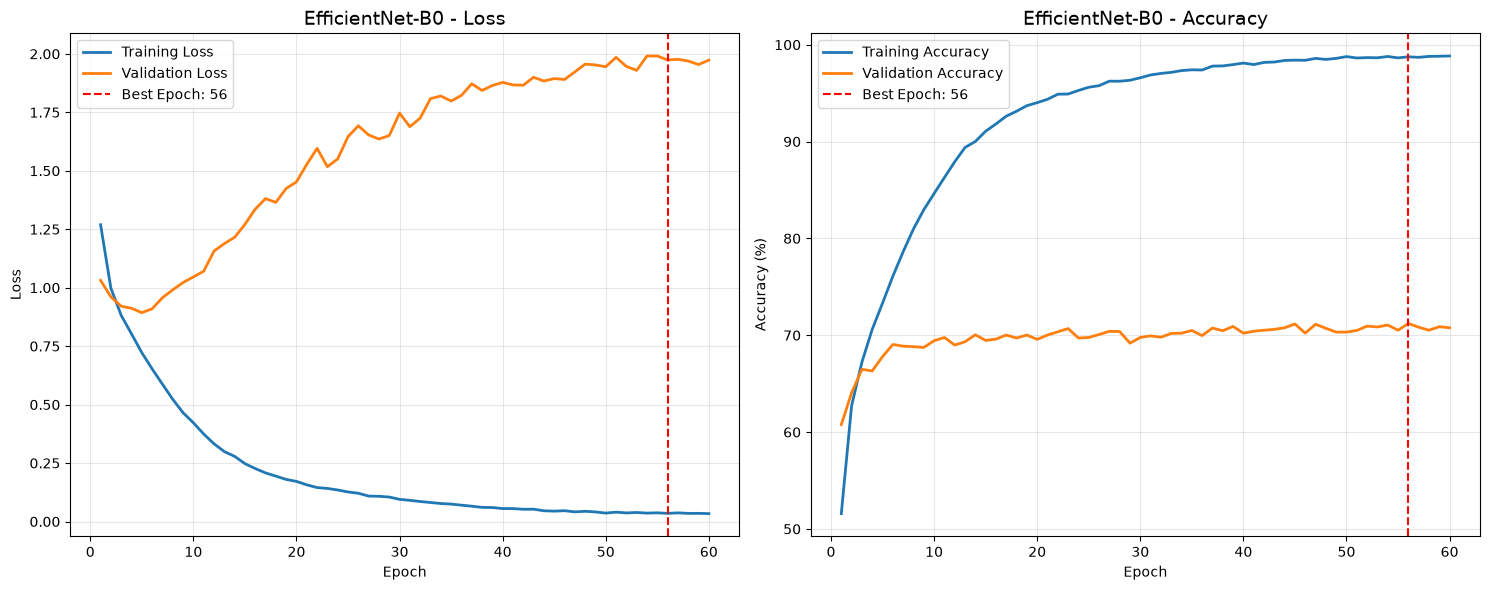


Dataset Loaded Successfully!
Validation Samples: 3589
Validation Batches: 113

Best EfficientNet-B0 model loaded successfully!

Computing predictions...
Processed 20/113 batches
Processed 40/113 batches
Processed 60/113 batches
Processed 80/113 batches
Processed 100/113 batches

Prediction completed!

OVERALL EVALUATION RESULTS
Accuracy:           71.22%
Macro Precision:    0.7096
Macro Recall:       0.6914
Macro F1-Score:     0.6986
Weighted Precision: 0.7112
Weighted Recall:    0.7122
Weighted F1-Score:  0.7109


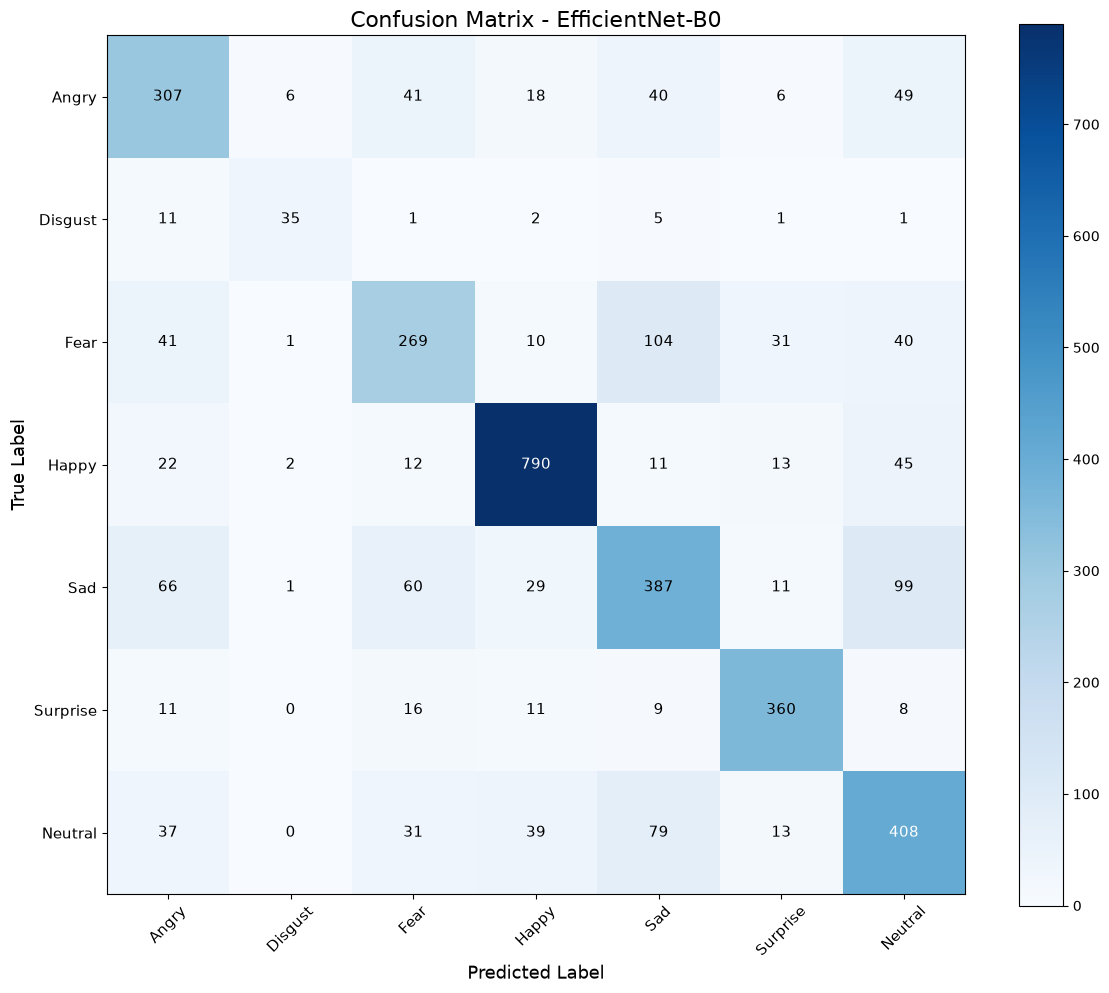


CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Angry     0.6202    0.6574    0.6383       467
     Disgust     0.7778    0.6250    0.6931        56
        Fear     0.6256    0.5423    0.5810       496
       Happy     0.8788    0.8827    0.8807       895
         Sad     0.6094    0.5926    0.6009       653
    Surprise     0.8276    0.8675    0.8471       415
     Neutral     0.6277    0.6722    0.6492       607

    accuracy                         0.7122      3589
   macro avg     0.7096    0.6914    0.6986      3589
weighted avg     0.7112    0.7122    0.7109      3589


CLASS-WISE ACCURACY
Happy       : 88.27%
Surprise    : 86.75%
Neutral     : 67.22%
Angry       : 65.74%
Disgust     : 62.50%
Sad         : 59.26%
Fear        : 54.23%

Strongest Classes:
Happy: 88.27%
Surprise: 86.75%
Neutral: 67.22%

Weakest Classes:
Disgust: 62.50%
Sad: 59.26%
Fear: 54.23%

EVALUATION COMPLETED SUCCESSFULLY!
Results saved in:
D:\ML\Computer Vision\EmotionDet

In [2]:

import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ==========================================
# 1. Project Configuration
# ==========================================

PROJECT_DIR = Path(
    r"D:\ML\Computer Vision\EmotionDetectionProject"
)

CSV_PATH = (
    PROJECT_DIR / "fer2013" / "fer2013" / "fer2013.csv"
)

HISTORY_PATH = (
    PROJECT_DIR / "outputs" / "efficientnet"
    / "training_history_efficientnet.json"
)

CHECKPOINT_PATH = (
    PROJECT_DIR / "checkpoints"
    / "best_efficientnet_emotion.pth"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "efficientnet"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class_names = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

print("=" * 60)
print("EfficientNet-B0 Evaluation")
print("=" * 60)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ==========================================
# 2. Check Required Files
# ==========================================

print("\nChecking project files...")

required_files = {
    "Dataset": CSV_PATH,
    "Training History": HISTORY_PATH,
    "Model Checkpoint": CHECKPOINT_PATH
}

for name, path in required_files.items():
    print(f"{name}: {'Found' if path.exists() else 'NOT FOUND'}")
    print("Path:", path)

    if not path.exists():
        raise FileNotFoundError(
            f"{name} not found: {path}"
        )


# ==========================================
# 3. Load Training History
# ==========================================

with open(HISTORY_PATH, "r", encoding="utf-8") as file:
    history = json.load(file)

required_keys = [
    "train_loss",
    "val_loss",
    "train_acc",
    "val_acc"
]

for key in required_keys:
    if key not in history:
        raise KeyError(
            f"'{key}' not found in training history."
        )

epochs = range(1, len(history["train_loss"]) + 1)

best_epoch = int(
    np.argmax(history["val_acc"]) + 1
)

best_val_accuracy = max(history["val_acc"])

print("\nBest Validation Accuracy:")
print(f"{best_val_accuracy:.2f}% at Epoch {best_epoch}")


# ==========================================
# 4. Plot Training Loss and Accuracy
# ==========================================

plt.figure(figsize=(15, 6))

# Loss
plt.subplot(1, 2, 1)

plt.plot(
    epochs,
    history["train_loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.axvline(
    x=best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.title("EfficientNet-B0 - Loss", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)


# Accuracy
plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    history["train_acc"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_acc"],
    label="Validation Accuracy",
    linewidth=2
)

plt.axvline(
    x=best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.title("EfficientNet-B0 - Accuracy", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "training_curves_efficientnet.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# 5. FER2013 Dataset Class
# ==========================================

class FER2013Dataset(Dataset):

    def __init__(
        self,
        csv_file,
        transform=None,
        usage="PublicTest"
    ):

        self.data = pd.read_csv(csv_file)

        self.data = self.data[
            self.data["Usage"] == usage
        ].reset_index(drop=True)

        self.transform = transform

        if len(self.data) == 0:
            raise ValueError(
                f"No samples found for Usage={usage}"
            )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        pixels = np.fromstring(
            self.data.iloc[idx]["pixels"],
            dtype=np.float32,
            sep=" "
        )

        if pixels.size != 2304:
            raise ValueError(
                f"Invalid image size at index {idx}"
            )

        image = pixels.reshape(48, 48).astype(np.uint8)

        image = Image.fromarray(image, mode="L")

        if self.transform:
            image = self.transform(image)

        label = int(
            self.data.iloc[idx]["emotion"]
        )

        return image, label


# ==========================================
# 6. Image Transformations
# ==========================================

test_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.Grayscale(
        num_output_channels=3
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ==========================================
# 7. Load PublicTest Dataset
# ==========================================

val_dataset = FER2013Dataset(
    csv_file=CSV_PATH,
    transform=test_transform,
    usage="PublicTest"
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("\nDataset Loaded Successfully!")
print("Validation Samples:", len(val_dataset))
print("Validation Batches:", len(val_loader))


# ==========================================
# 8. Load EfficientNet-B0 Model
# ==========================================

model = models.efficientnet_b0(
    weights=None
)

num_features = model.classifier[1].in_features

model.classifier[1] = torch.nn.Linear(
    num_features,
    7
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

# Supports both checkpoint formats
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )
else:
    model.load_state_dict(checkpoint)

model = model.to(device)

model.eval()

print("\nBest EfficientNet-B0 model loaded successfully!")


# ==========================================
# 9. Make Predictions
# ==========================================

all_preds = []
all_labels = []

print("\nComputing predictions...")

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(val_loader):

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_preds.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

        if (batch_idx + 1) % 20 == 0:
            print(
                f"Processed {batch_idx + 1}/{len(val_loader)} batches"
            )

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

print("\nPrediction completed!")


# ==========================================
# 10. Calculate Evaluation Metrics
# ==========================================

accuracy = accuracy_score(
    all_labels,
    all_preds
)

macro_precision = precision_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

weighted_precision = precision_score(
    all_labels,
    all_preds,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    all_labels,
    all_preds,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    all_labels,
    all_preds,
    average="weighted",
    zero_division=0
)

print("\n" + "=" * 60)
print("OVERALL EVALUATION RESULTS")
print("=" * 60)

print(f"Accuracy:           {accuracy * 100:.2f}%")
print(f"Macro Precision:    {macro_precision:.4f}")
print(f"Macro Recall:       {macro_recall:.4f}")
print(f"Macro F1-Score:     {macro_f1:.4f}")

print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1-Score:  {weighted_f1:.4f}")


# ==========================================
# 11. Confusion Matrix
# ==========================================

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(7))
)

plt.figure(figsize=(12, 10))

plt.imshow(
    cm,
    interpolation="nearest",
    cmap=plt.cm.Blues
)

plt.title(
    "Confusion Matrix - EfficientNet-B0",
    fontsize=16
)

plt.colorbar()

tick_marks = np.arange(len(class_names))

plt.xticks(
    tick_marks,
    class_names,
    rotation=45,
    fontsize=11
)

plt.yticks(
    tick_marks,
    class_names,
    fontsize=11
)

threshold = cm.max() / 2.0

for i in range(cm.shape[0]):

    for j in range(cm.shape[1]):

        plt.text(
            j,
            i,
            format(cm[i, j], "d"),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=11
        )

plt.ylabel("True Label", fontsize=13)
plt.xlabel("Predicted Label", fontsize=13)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "confusion_matrix_efficientnet.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# 12. Classification Report
# ==========================================

report = classification_report(
    all_labels,
    all_preds,
    labels=list(range(7)),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(report)


# ==========================================
# 13. Class-wise Accuracy
# ==========================================

class_accuracies = {}

for i, class_name in enumerate(class_names):

    total = cm[i].sum()

    correct = cm[i, i]

    class_accuracy = (
        correct / total * 100
        if total > 0 else 0
    )

    class_accuracies[class_name] = class_accuracy


sorted_accuracies = sorted(
    class_accuracies.items(),
    key=lambda x: x[1],
    reverse=True
)

print("\n" + "=" * 60)
print("CLASS-WISE ACCURACY")
print("=" * 60)

for class_name, acc in sorted_accuracies:

    print(f"{class_name:12s}: {acc:.2f}%")


print("\nStrongest Classes:")

for class_name, acc in sorted_accuracies[:3]:

    print(f"{class_name}: {acc:.2f}%")


print("\nWeakest Classes:")

for class_name, acc in sorted_accuracies[-3:]:

    print(f"{class_name}: {acc:.2f}%")


# ==========================================
# 14. Save Evaluation Results
# ==========================================

summary = {
    "model": "EfficientNet-B0",
    "evaluated_split": "PublicTest",
    "best_epoch": best_epoch,
    "best_validation_accuracy": float(best_val_accuracy),
    "evaluation_accuracy": float(accuracy * 100),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_precision": float(weighted_precision),
    "weighted_recall": float(weighted_recall),
    "weighted_f1": float(weighted_f1),
    "class_accuracies": {
        name: float(value)
        for name, value in class_accuracies.items()
    }
}

with open(
    OUTPUT_DIR / "evaluation_summary_efficientnet.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )


with open(
    OUTPUT_DIR / "classification_report_efficientnet.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(report)

    file.write("\n\nOverall Metrics\n")

    file.write(
        json.dumps(
            summary,
            indent=4,
            ensure_ascii=False
        )
    )


print("\n" + "=" * 60)
print("EVALUATION COMPLETED SUCCESSFULLY!")
print("=" * 60)

print("Results saved in:")
print(OUTPUT_DIR)

print("\nGenerated files:")
print("- training_curves_efficientnet.png")
print("- confusion_matrix_efficientnet.png")
print("- classification_report_efficientnet.txt")
print("- evaluation_summary_efficientnet.json")


✅ احساس تشخیص داده شده: Fear
🎯 میزان اطمینان: 52.48%

📊 احتمالات برای تمام احساسات:
   Angry     :  0.03% 
   Disgust   :  0.00% 
   Fear      : 52.48% ██████████████████████████
   Happy     :  0.01% 
   Sad       :  0.01% 
   Surprise  :  0.01% 
   Neutral   : 47.46% ███████████████████████


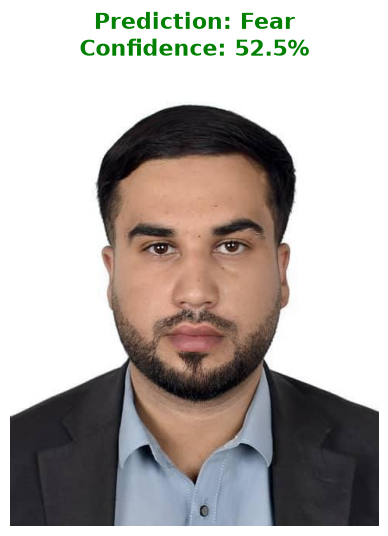

In [3]:
import torch
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
import torch.nn as nn
from pathlib import Path

# تنظیمات
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# لود مدل
model = models.efficientnet_b0(weights=None)
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 7)
model.load_state_dict(torch.load('best_efficientnet_emotion.pth', map_location=device))
model = model.to(device)
model.eval()

# Transform
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class_names = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']

# آدرس تصویر (تغییر دهید)
image_path = "test_image.jpg"  # یا مسیر کامل

try:
    # خواندن تصویر
    img = Image.open(image_path).convert('RGB')
    
    # پردازش
    input_tensor = transform(img).unsqueeze(0).to(device)
    
    # پیش‌بینی
    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.nn.functional.softmax(output, dim=1)[0]
        _, predicted_idx = torch.max(output, 1)
        
    predicted_emotion = class_names[predicted_idx.item()]
    confidence = probabilities[predicted_idx.item()].item() * 100
    
    # نمایش نتیجه
    print("="*60)
    print(f"✅ احساس تشخیص داده شده: {predicted_emotion}")
    print(f"🎯 میزان اطمینان: {confidence:.2f}%")
    print("="*60)
    
    # نمایش تمام احتمالات
    print("\n📊 احتمالات برای تمام احساسات:")
    for i, (name, prob) in enumerate(zip(class_names, probabilities)):
        bar = "█" * int(prob.item() * 50)
        print(f"   {name:10s}: {prob.item()*100:5.2f}% {bar}")
    
    # نمایش تصویر
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Prediction: {predicted_emotion}\nConfidence: {confidence:.1f}%", 
              fontsize=16, fontweight='bold', color='green')
    plt.axis('off')
    plt.show()
    
except FileNotFoundError:
    print(f"❌ خطا: فایل '{image_path}' پیدا نشد!")
    print("💡 لطفاً یک تصویر چهره در همین پوشه قرار دهید و نام آن را تغییر دهید.")
except Exception as e:
    print(f"❌ خطا: {e}")

In [2]:

# ============================================================
# REAL-TIME FACIAL EMOTION RECOGNITION
# Model: EfficientNet-B0
# Dataset: FER2013
# Face Detector: Haar Cascade
# ============================================================

import cv2
import torch
import torch.nn as nn
import numpy as np
import time

from pathlib import Path
from PIL import Image
from torchvision import transforms, models


# ============================================================
# 1. PROJECT CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    r"D:\ML\Computer Vision\EmotionDetectionProject"
)

CHECKPOINT_PATH = (
    PROJECT_DIR
    / "checkpoints"
    / "best_efficientnet_emotion.pth"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 55)
print("REAL-TIME EMOTION RECOGNITION")
print("=" * 55)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 2. CHECK OPENCV
# ============================================================

print("\nChecking OpenCV...")

print("OpenCV version:", cv2.__version__)
print("OpenCV location:", cv2.__file__)

if not hasattr(cv2, "CascadeClassifier"):
    raise RuntimeError(
        "OpenCV is not installed correctly.\n"
        "Run the OpenCV installation commands, "
        "restart the Jupyter kernel, and try again."
    )

if not hasattr(cv2, "data"):
    raise RuntimeError(
        "OpenCV Haar Cascade data is unavailable."
    )

print("OpenCV is working correctly!")


# ============================================================
# 3. LOAD EFFICIENTNET-B0 MODEL
# ============================================================

print("\nLoading EfficientNet-B0 model...")

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Model checkpoint not found:\n{CHECKPOINT_PATH}"
    )

model = models.efficientnet_b0(weights=None)

num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    7
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

# Support both checkpoint formats
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )
else:
    model.load_state_dict(checkpoint)

model = model.to(device)
model.eval()

print("Model loaded successfully!")


# ============================================================
# 4. LOAD HAAR CASCADE FACE DETECTOR
# ============================================================

print("\nLoading face detector...")

cascade_path = (
    Path(cv2.data.haarcascades)
    / "haarcascade_frontalface_default.xml"
)

if not cascade_path.exists():
    raise FileNotFoundError(
        f"Haar Cascade file not found:\n{cascade_path}"
    )

face_cascade = cv2.CascadeClassifier(
    str(cascade_path)
)

if face_cascade.empty():
    raise RuntimeError(
        "Could not load Haar Cascade classifier."
    )

print("Face detector loaded successfully!")


# ============================================================
# 5. IMAGE TRANSFORM
# Must match EfficientNet training preprocessing
# ============================================================

transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.Grayscale(
        num_output_channels=3
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])


# ============================================================
# 6. EMOTION LABELS AND COLORS
# ============================================================

class_names = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

emotion_colors = {

    "Angry": (0, 0, 255),

    "Disgust": (0, 128, 128),

    "Fear": (255, 0, 255),

    "Happy": (0, 255, 255),

    "Sad": (255, 128, 0),

    "Surprise": (255, 255, 0),

    "Neutral": (0, 255, 0)

}


# ============================================================
# 7. OPEN WEBCAM
# ============================================================

print("\nStarting webcam...")

cap = cv2.VideoCapture(0)

if not cap.isOpened():

    raise RuntimeError(
        "Could not open webcam. "
        "Check webcam connection and permissions."
    )

# Set webcam resolution
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

print("Webcam opened successfully!")

print("\nPress Q or ESC to exit.")


# ============================================================
# 8. REAL-TIME EMOTION DETECTION
# ============================================================

prev_time = time.time()

try:

    while True:

        # Read webcam frame
        ret, frame = cap.read()

        if not ret:
            print("Failed to capture frame.")
            break

        # Mirror webcam image
        frame = cv2.flip(frame, 1)

        # Convert to grayscale
        gray = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2GRAY
        )

        # Detect faces
        faces = face_cascade.detectMultiScale(
            gray,
            scaleFactor=1.2,
            minNeighbors=5,
            minSize=(80, 80)
        )

        # Process each detected face
        for (x, y, w, h) in faces:

            # Crop face
            face_roi = frame[
                y:y+h,
                x:x+w
            ]

            if face_roi.size == 0:
                continue

            # Convert BGR to RGB
            face_rgb = cv2.cvtColor(
                face_roi,
                cv2.COLOR_BGR2RGB
            )

            # Convert to PIL image
            face_pil = Image.fromarray(face_rgb)

            # Apply model preprocessing
            face_tensor = transform(
                face_pil
            ).unsqueeze(0).to(device)

            # Predict emotion
            with torch.no_grad():

                outputs = model(face_tensor)

                probabilities = torch.softmax(
                    outputs,
                    dim=1
                )[0]

                predicted_idx = torch.argmax(
                    probabilities
                ).item()

            predicted_emotion = class_names[
                predicted_idx
            ]

            confidence = (
                probabilities[predicted_idx].item()
                * 100
            )

            color = emotion_colors[
                predicted_emotion
            ]

            # Draw face rectangle
            cv2.rectangle(
                frame,
                (x, y),
                (x+w, y+h),
                color,
                2
            )

            # Draw emotion label
            label = (
                f"{predicted_emotion}: "
                f"{confidence:.1f}%"
            )

            label_y = max(y - 12, 25)

            cv2.putText(
                frame,
                label,
                (x, label_y),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                color,
                2
            )

            # Draw confidence bar background
            bar_y = min(y + h + 8, frame.shape[0] - 10)

            cv2.rectangle(
                frame,
                (x, bar_y),
                (x+w, bar_y+10),
                (80, 80, 80),
                -1
            )

            # Draw confidence bar
            bar_width = int(
                w * confidence / 100
            )

            cv2.rectangle(
                frame,
                (x, bar_y),
                (x+bar_width, bar_y+10),
                color,
                -1
            )

        # Calculate FPS
        current_time = time.time()

        elapsed = current_time - prev_time

        fps = 1 / elapsed if elapsed > 0 else 0

        prev_time = current_time

        # Display FPS
        cv2.putText(
            frame,
            f"FPS: {fps:.1f}",
            (15, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

        # Display detected face count
        cv2.putText(
            frame,
            f"Faces: {len(faces)}",
            (15, 70),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

        # Display webcam window
        cv2.imshow(
            "EfficientNet-B0 Emotion Recognition",
            frame
        )

        # Exit using Q or ESC
        key = cv2.waitKey(1) & 0xFF

        if key == ord("q") or key == 27:
            print("\nClosing webcam...")
            break


# ============================================================
# 9. RELEASE RESOURCES
# ============================================================

finally:

    cap.release()

    cv2.destroyAllWindows()

    print("Webcam released successfully!")

    print("Emotion recognition stopped.")


REAL-TIME EMOTION RECOGNITION
Using device: cuda
GPU: NVIDIA RTX A4000 Laptop GPU

Checking OpenCV...
OpenCV version: 4.11.0
OpenCV location: D:\ML\Computer Vision\EmotionDetectionProject\.venv\Lib\site-packages\cv2\__init__.py
OpenCV is working correctly!

Loading EfficientNet-B0 model...
Model loaded successfully!

Loading face detector...
Face detector loaded successfully!

Starting webcam...
Webcam opened successfully!

Press Q or ESC to exit.

Closing webcam...
Webcam released successfully!
Emotion recognition stopped.
